# Monthly returns for every stock

Source: `01_data/raw/chars_final_with_names.parquet`. Uses **actual current-month USD return (`ret`)**, not predictions or the forward target. Decimal returns: 0.05 = 5%. PERMNO identifies securities; supplied ticker/name labels can be missing or change over time.

Exports all stocks in long and wide CSV formats. Missing returns stay blank. Charts overlay all securities without filling gaps. The second panel zooms the y-axis to ±50%; the first panel and CSVs preserve the full range. No portfolio weighting or cumulative compounding is applied.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.ticker import PercentFormatter
import matplotlib.dates as mdates
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "01_data/raw/chars_final_with_names.parquet").exists())
OUT = ROOT / "01_data/exports/monthly_stock_returns"
OUT.mkdir(parents=True, exist_ok=True)
df = pq.read_table(ROOT / "01_data/raw/chars_final_with_names.parquet",
                   columns=["permno", "ticker", "company_name", "date", "eom", "ret"]).to_pandas()
df["month"] = pd.to_datetime(df["eom"]).dt.to_period("M").astype(str)
df = df.rename(columns={"ret": "monthly_return", "date": "source_observation_date"})
df = df[["month", "permno", "ticker", "company_name", "source_observation_date", "monthly_return"]]
df = df.sort_values(["month", "permno"]).reset_index(drop=True)
assert not df.duplicated(["month", "permno"]).any(), "Duplicate stock-months"
assert not np.isinf(df.monthly_return.dropna()).any(), "Infinite returns"
wide = df.pivot(index="month", columns="permno", values="monthly_return")
wide = wide.reindex(pd.period_range(wide.index.min(), wide.index.max(), freq="M").astype(str))
wide.index.name = "month"
df.to_csv(OUT / "monthly_stock_returns_long.csv", index=False)
wide.to_csv(OUT / "monthly_stock_returns_wide.csv")
# Check CSV dimensions, missingness, and numeric round-trip.
check = pd.read_csv(OUT / "monthly_stock_returns_long.csv")
assert len(check) == len(df)
assert check.monthly_return.isna().sum() == df.monthly_return.isna().sum()
np.testing.assert_allclose(check.monthly_return, df.monthly_return, equal_nan=True)
print(f"Exported {len(df):,} stock-months; {df.permno.nunique():,} securities; {len(wide)} months.")
print(f"Missing observed returns: {df.monthly_return.isna().sum():,}; preserved as blanks.")
display(df.head(10))
print(OUT)

Exported 529,082 stock-months; 6,561 securities; 140 months.
Missing observed returns: 0; preserved as blanks.


,month,permno,ticker,company_name,source_observation_date,monthly_return
0,2015-01,10001,EGAS,GAS NATURAL INC,2015-01-30,-0.115245
1,2015-01,10025,AEPI,A E P INDUSTRIES INC,2015-01-30,-0.138263
2,2015-01,10026,JJSF,J & J SNACK FOODS CORP,2015-01-30,-0.097913
3,2015-01,10028,DGSE,D G S E COMPANIES INC,2015-01-30,0.237705
4,2015-01,10032,PLXS,PLEXUS CORP,2015-01-30,-0.080563
5,2015-01,10044,RMCF,ROCKY MOUNTAIN CHOCOLATE FAC INC,2015-01-30,0.038872
6,2015-01,10051,HGR,HANGER INC,2015-01-30,-0.014612
7,2015-01,10104,ORCL,ORACLE CORP,2015-01-30,-0.065926
8,2015-01,10107,MSFT,MICROSOFT CORP,2015-01-30,-0.130248
9,2015-01,10116,ACUR,ACURA PHARMACEUTICALS INC,2015-01-30,0.222222


C:\Users\tonyt\Documents\hackathonfiam_zzz\01_data\exports\monthly_stock_returns


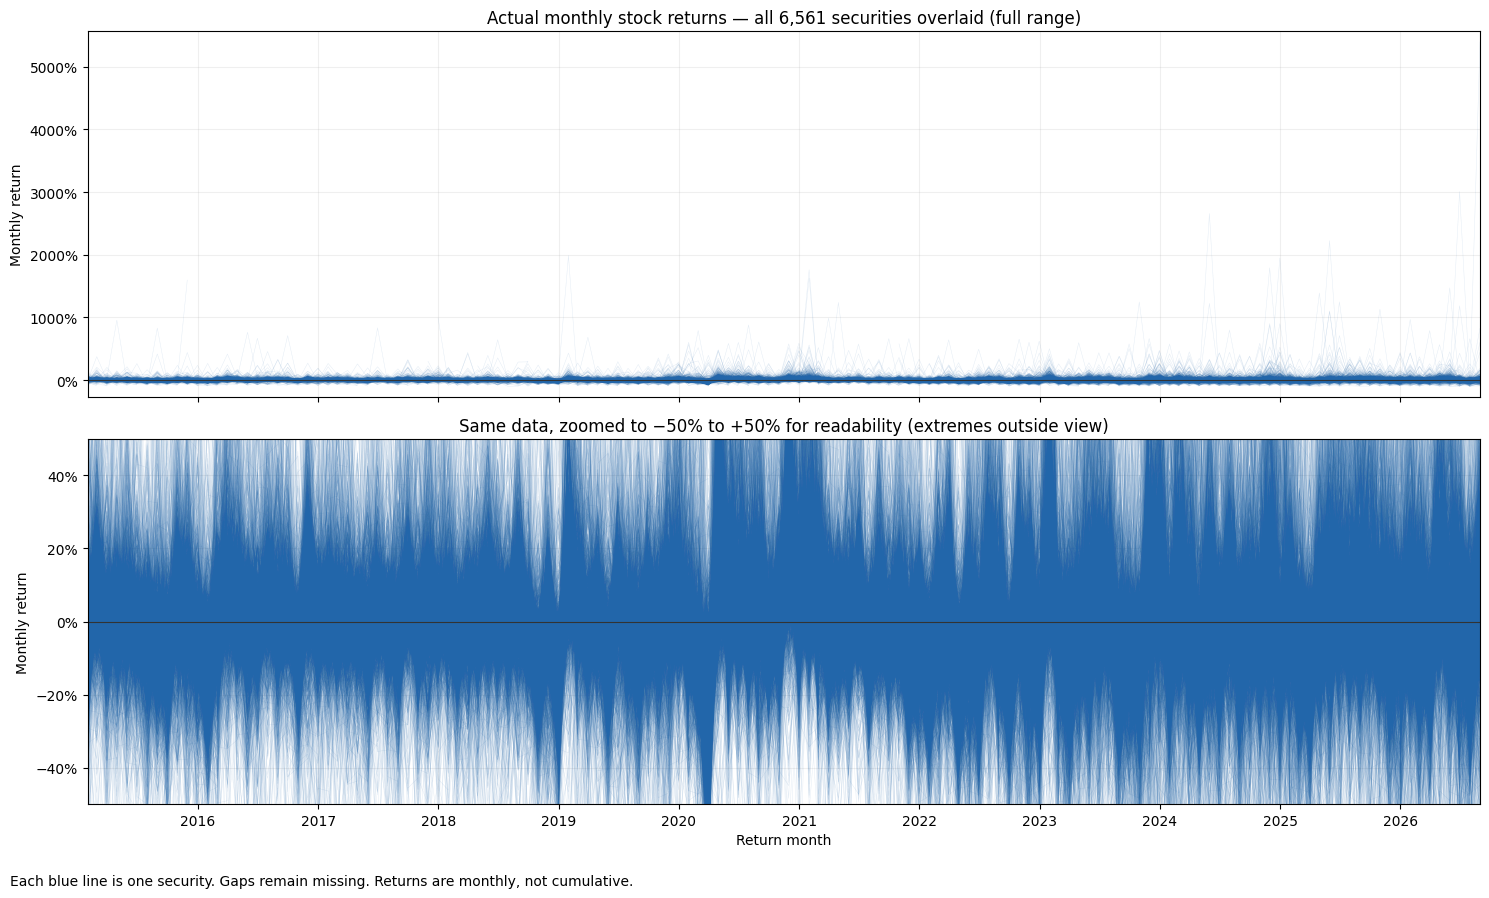

In [2]:
x = mdates.date2num(pd.PeriodIndex(wide.index, freq="M").to_timestamp("M"))
segments = [np.column_stack([x, wide[c].to_numpy(dtype=float)]) for c in wide.columns]
fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)
for ax in axes:
    ax.add_collection(LineCollection(segments, colors="#2266aa", linewidths=0.35, alpha=0.12,
                                     rasterized=True))
    ax.set_xlim(x.min(), x.max())
    ax.axhline(0, color="#333333", linewidth=0.8)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.set_ylabel("Monthly return")
    ax.grid(alpha=0.2)
lo, hi = df.monthly_return.min(), df.monthly_return.max()
pad = (hi - lo) * .03
axes[0].set_ylim(lo - pad, hi + pad)
axes[0].set_title(f"Actual monthly stock returns — all {len(wide.columns):,} securities overlaid (full range)")
axes[1].set_ylim(-.5, .5)
axes[1].set_title("Same data, zoomed to −50% to +50% for readability (extremes outside view)")
axes[1].set_xlabel("Return month")
fig.text(.01, .01, "Each blue line is one security. Gaps remain missing. Returns are monthly, not cumulative.", fontsize=10)
fig.tight_layout(rect=[0, .035, 1, 1])
fig.savefig(OUT / "monthly_stock_returns_overlay.png", dpi=160)
plt.show()